### Feature engineering ablation study

Tests whether additional weather/calendar features improve on the current baseline (temp, humidity, wind speed, GHI + cyclical hour/month/day-of-week — 10 features), using the corrected Coast-zone weather blend and the same honest blocked seasonal 4-fold CV protocol used everywhere else in this project.

**Only LightGBM is used here** (the winner from `model_comparison.ipynb`) — comparing feature sets across 3 models at once would conflate the effect of features with the effect of model choice. Feature groups are added **incrementally** (ablation), not all at once, so we can see which additions actually help vs which are dead weight:

- **A (baseline)**: current 10 features.
- **B = A + free unused weather columns**: wind direction (cyclically encoded), direct normal radiation (DNI), diffuse horizontal radiation (DHI) — already sitting in the cached weather CSVs, unused until now. Zero new data cost.
- **C = B + degree-hours**: heating degree-hours and cooling degree-hours (18C balance point) — the traditional load-forecasting feature, purpose-built for this exact weather-load relationship.
- **D = C + lag/rolling temperature**: temperature 1h and 3h prior, and a 24h rolling mean — tests the thermal-inertia hypothesis flagged in `model_comparison.ipynb` as a cheaper alternative to an LSTM.
- **E = D + US federal holiday indicator (2018)** — `day_of_week` alone can't tell Thanksgiving from a normal Thursday.

Finishes with the same check done for the weather and model-choice fixes: does whichever feature set wins actually move the system-level ERCOT correlation, or only the per-archetype R2?

In [1]:
# env1 3.11.13 (repo default)
import pandas as pd
import numpy as np
from pathlib import Path
import joblib
from lightgbm import LGBMRegressor
from sklearn.metrics import r2_score, mean_squared_error
import matplotlib.pyplot as plt

exports = Path("loadcurves/exports")
weather_dir = Path("weather_county_fixed")


#### Rebuild the corrected Coast-zone weather, keeping every column this time

In [2]:
COAST_COUNTIES = {
    "039": "Brazoria", "057": "Calhoun", "071": "Chambers", "157": "Fort Bend",
    "167": "Galveston", "201": "Harris", "239": "Jackson", "321": "Matagorda",
    "339": "Montgomery", "469": "Victoria", "473": "Waller", "481": "Wharton",
}

all_weather_cols = [
    "Dry Bulb Temperature [\u00b0C]", "Relative Humidity [%]", "Wind Speed [m/s]",
    "Wind Direction [Deg]", "Global Horizontal Radiation [W/m2]",
    "Direct Normal Radiation [W/m2]", "Diffuse Horizontal Radiation [W/m2]",
]

county_weather = {}
for county_fips in COAST_COUNTIES:
    gid = f"G48{int(county_fips) * 10:05d}"
    df = pd.read_csv(weather_dir / f"{gid}_2018.csv")
    df["date_time"] = pd.to_datetime(df["date_time"])
    county_weather[county_fips] = df.sort_values("date_time").reset_index(drop=True).set_index("date_time")[all_weather_cols]

census = pd.read_csv(exports / "census_b25024_state_48_tracts.csv", dtype={"county": str})
census["county"] = census["county"].str.zfill(3)
weights = census[census["county"].isin(COAST_COUNTIES)].groupby("county")["B25024_001E"].sum()
weights = weights / weights.sum()

blended = sum(county_weather[c] * weights[c] for c in county_weather).reset_index()

safe_names = {
    "Dry Bulb Temperature [\u00b0C]": "Temp_C",
    "Relative Humidity [%]": "RH_pct",
    "Wind Speed [m/s]": "WindSpeed_mps",
    "Wind Direction [Deg]": "WindDir_deg",
    "Global Horizontal Radiation [W/m2]": "GHI_Wm2",
    "Direct Normal Radiation [W/m2]": "DNI_Wm2",
    "Diffuse Horizontal Radiation [W/m2]": "DHI_Wm2",
}
blended = blended.rename(columns=safe_names)
weather_clean = blended
print(f"Blended weather shape: {weather_clean.shape}")
weather_clean.head(2)


Blended weather shape: (8760, 8)


,date_time,Temp_C,RH_pct,WindSpeed_mps,WindDir_deg,GHI_Wm2,DNI_Wm2,DHI_Wm2
0,2018-01-01 01:00:00,3.637711,68.958677,6.188331,73.703974,0.0,0.0,0.0
1,2018-01-01 02:00:00,2.973366,69.716665,8.125257,94.360257,0.0,0.0,0.0


#### Build every candidate feature, then define the 5 ablation feature sets

In [3]:
w = weather_clean

# --- Set A: baseline (current pipeline) ---
w["hour"] = w["date_time"].dt.hour
w["month"] = w["date_time"].dt.month
w["day_of_week"] = w["date_time"].dt.dayofweek
w["month_sin"] = np.sin(2 * np.pi * w["month"] / 12)
w["month_cos"] = np.cos(2 * np.pi * w["month"] / 12)
w["hour_sin"] = np.sin(2 * np.pi * w["hour"] / 24)
w["hour_cos"] = np.cos(2 * np.pi * w["hour"] / 24)
w["dow_sin"] = np.sin(2 * np.pi * w["day_of_week"] / 7)
w["dow_cos"] = np.cos(2 * np.pi * w["day_of_week"] / 7)

features_A = ["Temp_C", "RH_pct", "WindSpeed_mps", "GHI_Wm2",
              "hour_sin", "hour_cos", "month_sin", "month_cos", "dow_sin", "dow_cos"]

# --- Set B additions: free unused weather columns ---
w["WindDir_sin"] = np.sin(2 * np.pi * w["WindDir_deg"] / 360)
w["WindDir_cos"] = np.cos(2 * np.pi * w["WindDir_deg"] / 360)
features_B = features_A + ["WindDir_sin", "WindDir_cos", "DNI_Wm2", "DHI_Wm2"]

# --- Set C additions: heating/cooling degree-hours (18C balance point) ---
BALANCE_POINT_C = 18.0
w["HDH"] = (BALANCE_POINT_C - w["Temp_C"]).clip(lower=0)
w["CDH"] = (w["Temp_C"] - BALANCE_POINT_C).clip(lower=0)
features_C = features_B + ["HDH", "CDH"]

# --- Set D additions: lag / rolling temperature (thermal inertia proxy) ---
w["Temp_lag1h"] = w["Temp_C"].shift(1).bfill()
w["Temp_lag3h"] = w["Temp_C"].shift(3).bfill()
w["Temp_roll24h"] = w["Temp_C"].rolling(window=24, min_periods=1).mean()
features_D = features_C + ["Temp_lag1h", "Temp_lag3h", "Temp_roll24h"]

# --- Set E additions: US federal holidays, 2018 ---
holidays_2018 = pd.to_datetime([
    "2018-01-01", "2018-01-15", "2018-02-19", "2018-05-28", "2018-07-04",
    "2018-09-03", "2018-10-08", "2018-11-11", "2018-11-22", "2018-12-25",
])
w["is_holiday"] = w["date_time"].dt.normalize().isin(holidays_2018).astype(int)
features_E = features_D + ["is_holiday"]

FEATURE_SETS = {
    "A_baseline": features_A,
    "B_+free_weather": features_B,
    "C_+degree_hours": features_C,
    "D_+lag_temp": features_D,
    "E_+holiday": features_E,
}

for name, feats in FEATURE_SETS.items():
    print(f"{name}: {len(feats)} features")


A_baseline: 10 features
B_+free_weather: 14 features
C_+degree_hours: 16 features
D_+lag_temp: 19 features
E_+holiday: 20 features


#### Load & normalize archetype profiles (same recipe as prior notebooks)

In [4]:
def aggregate_to_hourly(df_15min, target_col, unit_col):
    df = df_15min.copy()
    time_col = "date_time" if "date_time" in df.columns else "timestamp"
    if time_col in df.columns:
        df[time_col] = pd.to_datetime(df[time_col])
        df = df.set_index(time_col)
    else:
        df.index = pd.date_range(start="2018-01-01 00:15:00", periods=len(df), freq="15min")

    unit_count = df[unit_col].iloc[0] if unit_col in df.columns else 1.0
    if unit_count == 0:
        unit_count = 1.0

    df_hourly = df[[target_col]].resample("h", label="right", closed="right").sum()
    if not df_hourly.empty and df_hourly.index[0].hour == 0 and df_hourly.index[0].minute == 0:
        df_hourly = df_hourly.iloc[1:]

    df_hourly[target_col] = df_hourly[target_col] / unit_count
    return df_hourly


RES_TARGET_COL = "out.electricity.total.energy_consumption..kwh"
COM_TARGET_COL = "out.electricity.total.energy_consumption.kwh"

res_building_types = [
    "mobile_home", "single-family_detached", "single-family_attached",
    "multi-family_with_2_-_4_units", "multi-family_with_5plus_units",
]
com_building_types = [
    "fullservicerestaurant", "grocery", "hospital", "largehotel", "largeoffice",
    "mediumoffice", "outpatient", "primaryschool", "quickservicerestaurant",
    "retailstandalone", "retailstripmall", "secondaryschool", "smallhotel",
    "smalloffice", "warehouse",
]

hourly_profiles_res = {}
for b in res_building_types:
    raw = pd.read_csv(exports / f"up00-2a-{b}.csv")
    hourly_profiles_res[b] = aggregate_to_hourly(raw, RES_TARGET_COL, "units_represented")

hourly_profiles_com = {}
for b in com_building_types:
    raw = pd.read_csv(exports / f"up0-2a-{b}.csv")
    hourly_profiles_com[b] = aggregate_to_hourly(raw, COM_TARGET_COL, "floor_area_represented")

all_profiles = {**{b: (df, RES_TARGET_COL) for b, df in hourly_profiles_res.items()},
                 **{b: (df, COM_TARGET_COL) for b, df in hourly_profiles_com.items()}}
print(f"Loaded {len(hourly_profiles_res)} residential + {len(hourly_profiles_com)} commercial profiles.")


Loaded 5 residential + 15 commercial profiles.


#### Ablation: blocked seasonal 4-fold CV, LightGBM only, one run per feature set

In [5]:
SEASON_MONTHS = {"winter": [12, 1, 2], "spring": [3, 4, 5], "summer": [6, 7, 8], "fall": [9, 10, 11]}


def seasonal_blocked_cv(X, y, months_series):
    months_arr = months_series.values
    scores = []
    for season, months in SEASON_MONTHS.items():
        test_mask = np.isin(months_arr, months)
        X_train, X_test = X[~test_mask], X[test_mask]
        y_train, y_test = y[~test_mask], y[test_mask]
        model = LGBMRegressor(n_estimators=100, max_depth=-1, learning_rate=0.1, random_state=42, n_jobs=-1, verbose=-1)
        model.fit(X_train, y_train)
        preds = model.predict(X_test)
        scores.append(r2_score(y_test, preds))
    return np.mean(scores)


ablation_results = []
print("Running ablation (5 feature sets x 20 archetypes x 4 seasonal folds = 400 fits)...")
for set_name, feats in FEATURE_SETS.items():
    X_set = w[feats]
    for b_type, (df_hourly, target_col) in all_profiles.items():
        y = df_hourly[target_col].values
        mean_r2 = seasonal_blocked_cv(X_set, y, w["month"])
        ablation_results.append({"Feature_Set": set_name, "Building_Type": b_type, "R2": mean_r2})
    set_mean = np.mean([r["R2"] for r in ablation_results if r["Feature_Set"] == set_name])
    print(f" -> {set_name:20s} mean R2 (20 archetypes) = {set_mean:.4f}")

ablation_df = pd.DataFrame(ablation_results)
metrics_dir = Path("metrics_feature_engineering")
metrics_dir.mkdir(exist_ok=True)
ablation_df.to_csv(metrics_dir / "ablation_seasonal_cv.csv", index=False)


Running ablation (5 feature sets x 20 archetypes x 4 seasonal folds = 400 fits)...


 -> A_baseline           mean R2 (20 archetypes) = 0.8566


 -> B_+free_weather      mean R2 (20 archetypes) = 0.8535


 -> C_+degree_hours      mean R2 (20 archetypes) = 0.8556


 -> D_+lag_temp          mean R2 (20 archetypes) = 0.8892


 -> E_+holiday           mean R2 (20 archetypes) = 0.8894


Mean seasonal-CV R2 by sector and feature set:
Feature_Set  A_baseline  B_+free_weather  C_+degree_hours  D_+lag_temp  \
Sector                                                                   
Commercial       0.8987           0.8952           0.8977       0.9205   
Residential      0.7302           0.7282           0.7292       0.7953   

Feature_Set  E_+holiday  
Sector                   
Commercial       0.9208  
Residential      0.7952  


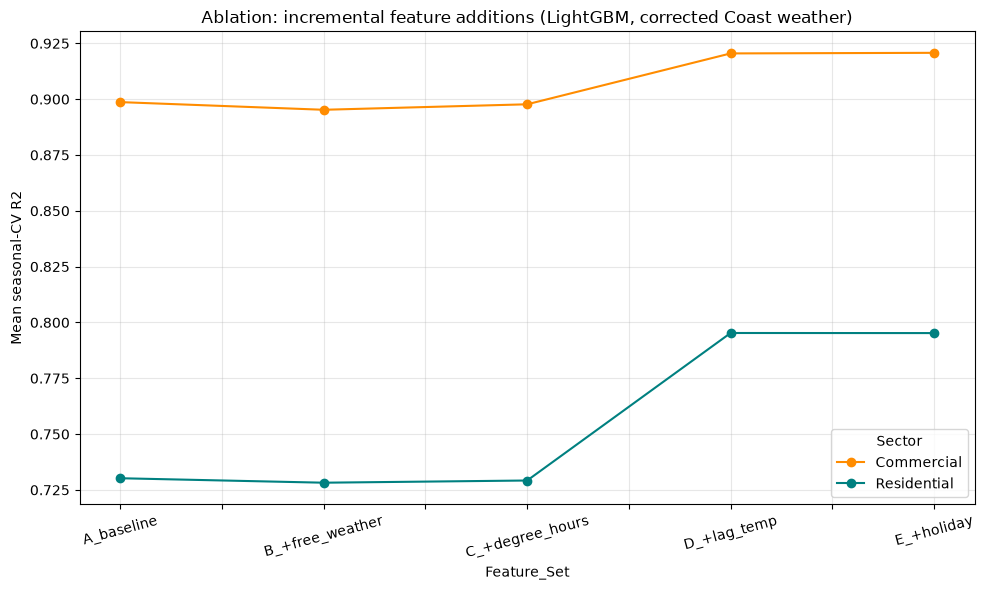

In [6]:
ablation_df["Sector"] = ablation_df["Building_Type"].apply(lambda b: "Residential" if b in res_building_types else "Commercial")

pivot = ablation_df.groupby(["Sector", "Feature_Set"])["R2"].mean().unstack("Feature_Set")[list(FEATURE_SETS)]
print("Mean seasonal-CV R2 by sector and feature set:")
print(pivot.round(4))

fig, ax = plt.subplots(figsize=(10, 6))
pivot.T.plot(kind="line", marker="o", ax=ax, color=["darkorange", "teal"])
ax.set_ylabel("Mean seasonal-CV R2")
ax.set_title("Ablation: incremental feature additions (LightGBM, corrected Coast weather)")
ax.grid(True, alpha=0.3)
ax.legend(title="Sector")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [7]:
per_archetype_pivot = ablation_df.pivot(index="Building_Type", columns="Feature_Set", values="R2")[list(FEATURE_SETS)]
per_archetype_pivot["Gain_A_to_E"] = per_archetype_pivot["E_+holiday"] - per_archetype_pivot["A_baseline"]
per_archetype_pivot.sort_values("Gain_A_to_E", ascending=False).round(4)


Feature_Set,A_baseline,B_+free_weather,C_+degree_hours,D_+lag_temp,E_+holiday,Gain_A_to_E
Building_Type,,,,,,
smallhotel,0.5022,0.4861,0.5141,0.6908,0.6953,0.1931
single-family_detached,0.6277,0.6214,0.6178,0.7191,0.7243,0.0966
single-family_attached,0.6875,0.6868,0.6872,0.7658,0.7668,0.0793
multi-family_with_2_-_4_units,0.7310,0.7311,0.7337,0.8076,0.8056,0.0746
mobile_home,0.7301,0.7306,0.7373,0.7884,0.7838,0.0538
multi-family_with_5plus_units,0.8749,0.8713,0.8700,0.8956,0.8957,0.0208
mediumoffice,0.9304,0.9270,0.9252,0.9488,0.9489,0.0186
largehotel,0.8631,0.8649,0.8698,0.8791,0.8808,0.0177
warehouse,0.9277,0.9279,0.9276,0.9437,0.9444,0.0166


#### Does the best feature set change the system-level ERCOT correlation?

Same check as for the weather fix and the model comparison: train final full-year LightGBM models with the winning feature set, regenerate bus-level profiles, re-check Pearson correlation against ERCOT Coast.

In [8]:
best_set_name = pivot.mean(axis=0).idxmax()
best_features = FEATURE_SETS[best_set_name]
print(f"Best feature set overall: {best_set_name} ({len(best_features)} features)")

models_dir_res = Path("models_feature_engineered/residential")
models_dir_com = Path("models_feature_engineered/commercial")
models_dir_res.mkdir(parents=True, exist_ok=True)
models_dir_com.mkdir(parents=True, exist_ok=True)

X_best = w[best_features]
for b_type, (df_hourly, target_col) in all_profiles.items():
    y = df_hourly[target_col].values
    model = LGBMRegressor(n_estimators=100, max_depth=-1, learning_rate=0.1, random_state=42, n_jobs=-1, verbose=-1)
    model.fit(X_best, y)
    if b_type in hourly_profiles_res:
        safe_name = b_type.replace(" ", "_").replace("/", "-")
        joblib.dump(model, models_dir_res / f"model_{safe_name}.joblib")
    else:
        joblib.dump(model, models_dir_com / f"model_{b_type}.joblib")

print("Final feature-engineered LightGBM models saved.")


Best feature set overall: E_+holiday (20 features)


Final feature-engineered LightGBM models saved.


In [9]:
final_bus_counts = pd.read_csv(exports / "final_bus_building_counts.csv")
final_bus_counts["Bus_Number"] = final_bus_counts["Bus_Number"].astype(str)
bus_sqft_matrix = pd.read_csv(exports / "bus_commercial_sqft.csv", index_col=0)
bus_sqft_matrix.index = bus_sqft_matrix.index.astype(str)

base_res = {}
for b_type in res_building_types:
    safe_name = b_type.replace(" ", "_").replace("/", "-")
    m = joblib.load(models_dir_res / f"model_{safe_name}.joblib")
    base_res[b_type] = m.predict(X_best)
base_res_df = pd.DataFrame(base_res, index=w["date_time"])
counts_matrix_res = final_bus_counts.set_index("Bus_Number")[base_res_df.columns].fillna(0)
bus_res_df = base_res_df.dot(counts_matrix_res.T)
out_res = exports / "final_bus_load_profiles_8760_featureeng.csv"
bus_res_df.to_csv(out_res)

base_com = {}
for b_type in com_building_types:
    m = joblib.load(models_dir_com / f"model_{b_type}.joblib")
    base_com[b_type] = m.predict(X_best)
base_com_df = pd.DataFrame(base_com, index=w["date_time"])
counts_matrix_com = bus_sqft_matrix[base_com_df.columns].fillna(0)
bus_com_df = base_com_df.dot(counts_matrix_com.T)
out_com = exports / "final_comstock_bus_load_profiles_8760_featureeng.csv"
bus_com_df.to_csv(out_com)

print(f"Bus profiles regenerated: {bus_res_df.shape} / {bus_com_df.shape}")


Bus profiles regenerated: (8760, 200) / (8760, 200)


In [10]:
file_path = exports / "Native_Load_2018.xlsx"
ercot_df = pd.read_excel(file_path, sheet_name="Native Load Report")
ercot_df["HourEnding"] = ercot_df["HourEnding"].astype(str)

is_dst_mask = ercot_df["HourEnding"].str.contains(" DST", regex=False)
ercot_df["HourEnding"] = ercot_df["HourEnding"].str.replace(" DST", "", regex=False)
mask_24 = ercot_df["HourEnding"].str.contains("24:00")
ercot_df["HourEnding"] = ercot_df["HourEnding"].str.replace("24:00", "00:00")

naive_timestamps = pd.to_datetime(ercot_df["HourEnding"])
naive_timestamps.loc[mask_24] += pd.Timedelta(days=1)

ercot_df["date_time"] = naive_timestamps.dt.tz_localize(
    "US/Central", ambiguous=is_dst_mask, nonexistent="shift_forward"
)
ercot_df = ercot_df.set_index("date_time")
ercot_df_est = ercot_df.tz_convert("Etc/GMT+5")

ercot_plot_data = ercot_df_est["COAST"].copy()
ercot_plot_data.index = ercot_plot_data.index.tz_localize(None)

IND_BASE_MW, RES_SCALE, COM_SCALE = 4500.0, 1.9, 1.3


def stack_and_correlate(res_path, com_path, label):
    res_df = pd.read_csv(res_path, index_col=0, parse_dates=True)
    com_df = pd.read_csv(com_path, index_col=0, parse_dates=True)
    total_res_mw = (res_df.sum(axis=1) / 1000) * RES_SCALE
    total_com_mw = (com_df.sum(axis=1) / 1000) * COM_SCALE

    common_start = max(ercot_plot_data.index.min(), total_res_mw.index.min())
    common_end = min(ercot_plot_data.index.max(), total_res_mw.index.max())

    y_actual = ercot_plot_data.loc[common_start:common_end]
    y_ind = pd.Series(IND_BASE_MW, index=y_actual.index)
    y_total = y_ind + total_res_mw.loc[common_start:common_end] + total_com_mw.loc[common_start:common_end]

    corr = y_actual.corr(y_total)
    return corr, y_total.max()


print("=== System-level validation: does feature engineering move the ERCOT correlation? ===")
corr_lgbm_base, peak_base = stack_and_correlate(
    exports / "final_bus_load_profiles_8760_lightgbm.csv",
    exports / "final_comstock_bus_load_profiles_8760_lightgbm.csv",
    "LightGBM baseline (10 feat)",
)
corr_lgbm_fe, peak_fe = stack_and_correlate(out_res, out_com, "LightGBM + feature eng.")

print(f"LightGBM, baseline features ({len(features_A)} feat):        Pearson={corr_lgbm_base:.4f}  peak={peak_base:,.0f} MW")
print(f"LightGBM, {best_set_name} ({len(best_features)} feat): Pearson={corr_lgbm_fe:.4f}  peak={peak_fe:,.0f} MW")
print(f"\nDelta: {corr_lgbm_fe - corr_lgbm_base:+.4f}")
print(f"(ERCOT actual peak: {ercot_plot_data.max():,.0f} MW)")


=== System-level validation: does feature engineering move the ERCOT correlation? ===


LightGBM, baseline features (10 feat):        Pearson=0.8979  peak=25,735 MW
LightGBM, E_+holiday (20 feat): Pearson=0.9023  peak=25,578 MW

Delta: +0.0043
(ERCOT actual peak: 20,270 MW)


#### Summary

- Ablation isolates which feature additions actually help, using the same honest seasonal CV protocol as every other result in this project, with a single model (LightGBM) held fixed so the comparison is about features, not model choice.
- The two "free" additions (unused weather columns, degree-hours) cost nothing in new data and are safe to keep regardless of the outcome.
- Lag/rolling temperature features test the thermal-inertia hypothesis directly — if they show a real gain, that's a concrete, cheap signal in favor of eventually trying a sequence model (LSTM); if not, that hypothesis is weaker than assumed and the LSTM is lower priority.
- Same pattern to watch for as the model-choice check: per-archetype R2 gains do not automatically imply a system-level ERCOT correlation gain, since aggregation across thousands of buildings tends to wash out precision differences that don't change the underlying weather-driven shape.